# STM metro incidents: analysis notebook

This notebook is the narrative of the analysis. Reusable code lives in `src/`;
the cells here call it and show the evidence.

**Part 1 (this section): exploration.** Its only purpose is to inform two later
decisions: how to define a major interruption (target) and which fields can be
used to predict it (features). No target, feature set or model is chosen here.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the repository root importable, whether the notebook is run from the
# repository root or from the notebooks/ folder.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import data, eda, verify

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)
print("Python interpreter:", sys.executable)

Python interpreter: /Users/elcinergin/Library/Mobile Documents/com~apple~CloudDocs/Learn_Apply/2026_JobApplication/TobogganLabs/takehome/DS_challenge/.venv.nosync/bin/python


In [2]:
# Rebuild the cleaned tables from the raw files, so the notebook always starts
# from raw data. The raw tables are loaded too, for the verification checks.
incidents, km = data.build()
incidents_raw = data.load_incidents_raw()
km_raw = data.load_km_raw()

# Most of the exploration looks at train incidents (see section 1 for why).
train = eda.train_incidents(incidents)
print(f"{len(incidents):,} incidents, of which {len(train):,} train incidents")
print(f"{len(km):,} planned-km rows")

45,561 incidents, of which 29,167 train incidents
8,472 planned-km rows


## 1. Verifying the initial observations

`PLAN.md` lists observations made during a first quick look at the files. Each
one is re-checked here with an explicit test. `CORRECTED` means the first
impression was wrong or incomplete; `from dictionary` means the statement comes
from the data dictionary and cannot be tested with the data.

In [3]:
checks = verify.verify_observations(incidents_raw, km_raw, incidents, km)
print(checks["status"].value_counts().to_string())
checks

status
confirmed          23
CORRECTED           5
from dictionary     5


,observation,check,expected,found,status
0,"Both .xls files are plain text, not Excel workbooks",first bytes are an Excel signature,False,False,confirmed
1,"Incidents file: 45,561 rows x 26 columns",shape of the raw table,"(45561, 26)","(45561, 26)",confirmed
2,"Planned-km file: 8,472 rows x 11 columns",shape of the raw table,"(8472, 11)","(8472, 11)",confirmed
3,"Incidents file starts with a byte-order mark, km file does not",first three bytes of each file,"(True, False)","(True, False)",confirmed
4,Exactly one line value is corrupted (02-avr),values of `line` that are not a line,['02-avr'],['02-avr'],confirmed
5,Year/month is stored as text such as janv-19,share of values shaped like letters-two digits,1.0,1.0,confirmed
6,Times run from 02:00 to 27:41,"earliest start time and latest end time, as hours:minutes",2:00 to 27:41,2:00 to 29:30,CORRECTED
7,Times mix HH:MM and HH:MM:SS formats,text lengths found in the start time,"[5, 8]","[5, 8]",confirmed
8,"Year, month, day and weekday follow the service day",share of rows where weekday matches the service date,1.0,1.0,confirmed
9,Calendar date is one day later exactly when the start time is past 24:00,rows with a later calendar date but a start time before 24:00,0,60,CORRECTED


**The five corrections**

1. Times run to 29:30, not 27:41 (the first look only covered train incidents).
2. The calendar date is one day after the service date for every incident
   starting at 24:00 or later, as expected, but also for 60 incidents that start
   at exactly `02:00`. These look like incidents at the very end of the service
   day, written as 02:00 instead of 26:00.
3. Zero-km duplicate rows also exist in 2020 (76 rows), not only in 2019.
4. The zero-km row is not always the one without a service period: for 868
   line/days the planned km sits on the row without a period.
5. Rolling stock type mirrors the secondary cause in all but 4 rows.

In [4]:
# Correction 5 in detail: rolling stock type against secondary cause.
pd.crosstab(
    incidents["rolling_stock_type"],
    incidents["secondary_cause"].where(
        incidents["secondary_cause"].isin(["MR-73", "MPM-10"]), "any other cause"
    ),
)

secondary_cause,MPM-10,MR-73,any other cause
rolling_stock_type,,,
10,1226,0,4
73,0,2915,0
Non affecté,0,0,41416


## 2. Evidence for the target decision

### 2.1 Why train incidents

Every station incident sits in the lowest duration bin, and the dictionary
states that station incidents do not affect metro service. Duration therefore
only varies among train incidents.

In [5]:
pd.crosstab(incidents["duration_bin"], incidents["incident_type"], margins=True)

incident_type,S,T,All
duration_bin,,,
02 min et moins,16394,16450,32844
03 à 04 min,0,6304,6304
05 à 09 min,0,4377,4377
10 à 14 min,0,933,933
15 à 19 min,0,299,299
20 à 24 min,0,173,173
25 à 29 min,0,107,107
30 min et plus,0,524,524
All,16394,29167,45561


### 2.2 How long train incidents last, and is that stable over time?

The table gives, per year, the number of train incidents and the share lasting
at least 5, 10, 15 and 30 minutes. 2025 covers January to September only.

In [6]:
by_year = eda.duration_summary(train, "service_year")
# Number of incidents behind each share, to judge how noisy each one is.
for minutes in eda.THRESHOLDS:
    by_year[f"n_{minutes}min_plus"] = (
        by_year[f"share_{minutes}min_plus"] * by_year["incidents"]
    ).round().astype(int)
by_year.style.format({c: "{:.1%}" for c in by_year.columns if c.startswith("share")})

,incidents,share_5min_plus,share_10min_plus,share_15min_plus,share_30min_plus,n_5min_plus,n_10min_plus,n_15min_plus,n_30min_plus
service_year,,,,,,,,,
2019,5081,19.0%,5.4%,2.8%,1.3%,964,275,143,67
2020,3709,21.5%,6.8%,3.9%,2.1%,799,253,146,77
2021,3564,22.4%,7.4%,4.1%,2.1%,800,262,145,75
2022,4207,21.3%,6.6%,3.7%,1.9%,896,276,157,78
2023,4497,24.4%,7.7%,3.8%,1.6%,1097,345,169,71
2024,5063,22.1%,7.8%,4.4%,2.0%,1121,396,222,102
2025,3046,24.2%,7.5%,4.0%,1.8%,736,229,121,54


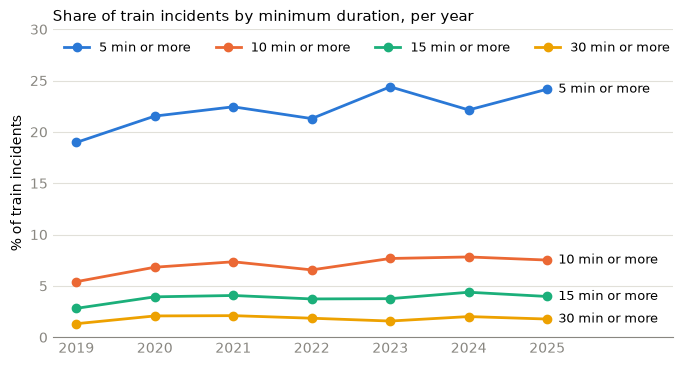

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = {5: "5 min or more", 10: "10 min or more", 15: "15 min or more", 30: "30 min or more"}
for minutes, color in zip(eda.THRESHOLDS, eda.SERIES_COLORS):
    share = by_year[f"share_{minutes}min_plus"] * 100
    ax.plot(share.index, share, color=color, linewidth=2, marker="o", label=labels[minutes])
    # Direct label at the end of each line.
    ax.annotate(labels[minutes], (share.index[-1], share.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_ylim(0, 30)
ax.set_xlim(2018.7, 2026.6)
ax.set_xticks(by_year.index)
eda.style_axes(ax, "Share of train incidents by minimum duration, per year", "% of train incidents")
ax.legend(frameon=False, loc="upper left", ncol=4, fontsize=9)
plt.show()

In [8]:
# Same summary by line. Combinations of lines are grouped together.
by_line = eda.duration_summary(train, "line_group")
by_line.style.format({c: "{:.1%}" for c in by_line.columns if c.startswith("share")})

,incidents,share_5min_plus,share_10min_plus,share_15min_plus,share_30min_plus
line_group,,,,,
Ligne bleue,3232,22.1%,6.3%,3.1%,1.6%
Ligne jaune,2153,19.5%,5.3%,2.7%,0.9%
Ligne orange,11506,21.3%,6.3%,3.5%,1.6%
Ligne verte,11827,22.7%,7.4%,3.8%,1.7%
Multiple lines or other,449,32.3%,24.1%,21.6%,13.8%


### 2.3 Volume over time

Monthly train incidents, all durations (top) and 5 minutes or more (bottom).
The dashed line marks March 2020 (start of COVID-19 restrictions); the shaded
band marks the last three months of data, which the dictionary says can still
be incomplete.

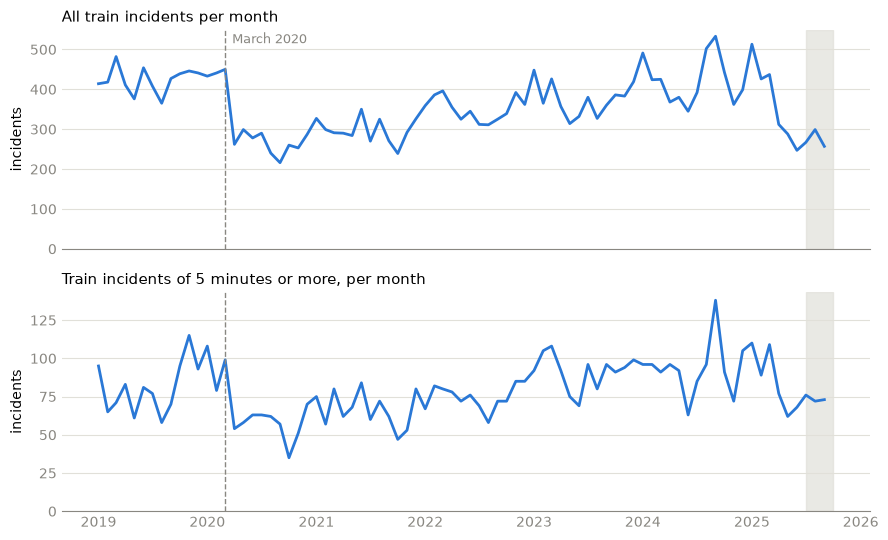

In [9]:
# One row per month: count all train incidents and those of 5 minutes or more.
train["month_start"] = train["service_date"].dt.to_period("M").dt.to_timestamp()
monthly = train.groupby("month_start").agg(
    incidents=("incident_id", "size"),
    incidents_5min_plus=("duration_bin_lower", lambda s: (s >= 5).sum()),
)

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
titles = {"incidents": "All train incidents per month",
          "incidents_5min_plus": "Train incidents of 5 minutes or more, per month"}
last_month = monthly.index.max()
for ax, column in zip(axes, titles):
    ax.plot(monthly.index, monthly[column], color=eda.SERIES_COLORS[0], linewidth=2)
    ax.axvline(pd.Timestamp("2020-03-01"), color=eda.MUTED_COLOR, linestyle="--", linewidth=1)
    ax.axvspan(last_month - pd.DateOffset(months=2), last_month + pd.DateOffset(months=1),
               color=eda.GRID_COLOR, alpha=0.7)
    ax.set_ylim(0, None)
    eda.style_axes(ax, titles[column], "incidents")
axes[0].annotate("March 2020", (pd.Timestamp("2020-03-01"), monthly["incidents"].max()),
                 xytext=(5, -5), textcoords="offset points", fontsize=9, color=eda.MUTED_COLOR)
plt.tight_layout()
plt.show()

In [10]:
# Table behind the figure, summarised per year (monthly average), plus the
# last six months compared with the same months one year earlier.
print(monthly.groupby(monthly.index.year).mean().round(0).rename_axis("year").to_string())

last_six = monthly.tail(6).copy()
same_months_last_year = monthly.loc[last_six.index - pd.DateOffset(years=1), "incidents"]
last_six["incidents_one_year_earlier"] = same_months_last_year.to_numpy()
last_six

      incidents  incidents_5min_plus
year                                
2019      423.0                 80.0
2020      309.0                 67.0
2021      297.0                 67.0
2022      351.0                 75.0
2023      375.0                 91.0
2024      422.0                 93.0
2025      338.0                 82.0


,incidents,incidents_5min_plus,incidents_one_year_earlier
month_start,,,
2025-04-01,312,77,368
2025-05-01,288,62,380
2025-06-01,247,68,345
2025-07-01,267,76,392
2025-08-01,299,72,502
2025-09-01,257,73,533


The last six months are well below the same months one year earlier. To see
whether that is a general drop or limited to short incidents, the next table
counts April to September of each year, split by duration.

In [11]:
# April to September of each year: short incidents against 5 minutes or more.
spring_summer = train[train["service_month"].between(4, 9)]
april_september = spring_summer.groupby("service_year").agg(
    under_5min=("duration_bin_lower", lambda s: (s < 5).sum()),
    five_min_plus=("duration_bin_lower", lambda s: (s >= 5).sum()),
)
april_september["share_5min_plus"] = (
    april_september["five_min_plus"] / april_september.sum(axis=1)
).round(3)
april_september

,under_5min,five_min_plus,share_5min_plus
service_year,,,
2019,2011,430,0.176
2020,1228,357,0.225
2021,1382,408,0.228
2022,1548,425,0.215
2023,1562,508,0.245
2024,1950,570,0.226
2025,1242,428,0.256


### 2.4 Reliability view: incidents per million planned km

Raw counts mix reliability with how much service was run. Dividing by planned
kilometres separates the two. This is only possible where km data exists
(January 2019 to September 2023) and for incidents assigned to a single line.
2023 covers January to September for both incidents and km.

In [12]:
# Coverage of the km denominator.
last_km_date = data.daily_km(km)["calendar_date"].max()
in_km_period = train["service_date"] <= last_km_date
on_single_line = train["line"].isin(data.SINGLE_LINES)
print(f"Train incidents in the km period: {in_km_period.mean():.1%}")
print(f"Train incidents on a single line: {on_single_line.mean():.1%}")
print(f"Train incidents with a km denominator (both): {(in_km_period & on_single_line).mean():.1%}")

rates = eda.incidents_per_million_km(train, km)
assert rates["incidents"].sum() == (in_km_period & on_single_line).sum()   # reconciles
rates.round(1)

Train incidents in the km period: 68.1%
Train incidents on a single line: 98.5%
Train incidents with a km denominator (both): 67.2%


incidents  incidents_5min_plus  million_km  \
year line                                                       
2019 Ligne bleue         604                  112         8.4   
     Ligne jaune         382                   51         4.9   
     Ligne orange       2082                  380        44.0   
     Ligne verte        1948                  399        32.6   
2020 Ligne bleue         436                   83         8.3   
     Ligne jaune         213                   35         4.8   
     Ligne orange       1492                  300        42.8   
     Ligne verte        1521                  372        32.2   
2021 Ligne bleue         341                   71         7.9   
     Ligne jaune         194                   42         4.6   
     Ligne orange       1493                  329        41.1   
     Ligne verte        1486                  338        30.8   
2022 Ligne bleue         480                  114         7.9   
     Ligne jaune         293                   42         4.6   
     Ligne orange       1613                  331        41.1   
     Ligne verte        1777                  405        30.8   
2023 Ligne bleue         345                   81         5.7   
     Ligne jaune         221                   43         4.6   
     Ligne orange       1196                  295        29.8   
     Ligne verte        1495                  380        21.4   

                   incidents_per_million_km  \
year line                                     
2019 Ligne bleue                       71.5   
     Ligne jaune                       78.0   
     Ligne orange                      47.3   
     Ligne verte                       59.8   
2020 Ligne bleue                       52.5   
     Ligne jaune                       44.8   
     Ligne orange                      34.9   
     Ligne verte                       47.3   
2021 Ligne bleue                       43.4   
     Ligne jaune                       42.6   
     Ligne orange                      36.3   
     Ligne verte                       48.2   
2022 Ligne bleue                       61.0   
     Ligne jaune                       64.3   
     Ligne orange                      39.2   
     Ligne verte                       57.7   
2023 Ligne bleue                       60.0   
     Ligne jaune                       48.5   
     Ligne orange                      40.1   
     Ligne verte                       69.8   

                   incidents_5min_plus_per_million_km  
year line                                              
2019 Ligne bleue                                 13.3  
     Ligne jaune                                 10.4  
     Ligne orange                                 8.6  
     Ligne verte                                 12.3  
2020 Ligne bleue                                 10.0  
     Ligne jaune                                  7.4  
     Ligne orange                                 7.0  
     Ligne verte                                 11.6  
2021 Ligne bleue                                  9.0  
     Ligne jaune                                  9.2  
     Ligne orange                                 8.0  
     Ligne verte                                 11.0  
2022 Ligne bleue                                 14.5  
     Ligne jaune                                  9.2  
     Ligne orange                                 8.0  
     Ligne verte                                 13.1  
2023 Ligne bleue                                 14.1  
     Ligne jaune                                  9.4  
     Ligne orange                                 9.9  
     Ligne verte                                 17.7

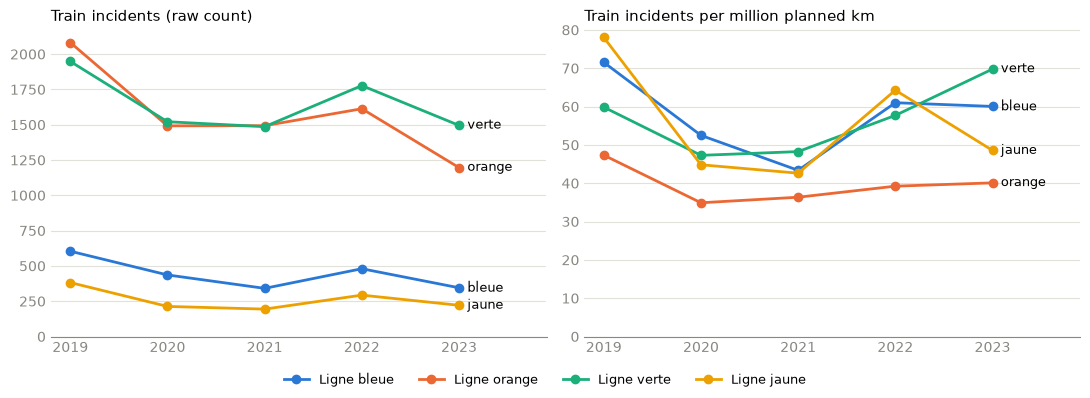

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
panels = {"incidents": "Train incidents (raw count)",
          "incidents_per_million_km": "Train incidents per million planned km"}
for ax, column in zip(axes, panels):
    for line, color in eda.LINE_COLORS.items():
        series = rates.xs(line, level="line")[column]
        ax.plot(series.index, series, color=color, linewidth=2, marker="o", label=line)
        ax.annotate(line.replace("Ligne ", ""), (series.index[-1], series.iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_ylim(0, None)
    ax.set_xlim(2018.8, 2023.9)
    ax.set_xticks(range(2019, 2024))
    eda.style_axes(ax, panels[column])
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, frameon=False, fontsize=9, ncol=4, loc="lower center")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [14]:
# Planned km per line and year, to read the rates against. 2023 has 9 months.
planned = data.daily_km(km)
planned["year"] = planned["calendar_date"].dt.year
km_table = (planned.groupby(["year", "line"])["planned_km"].sum() / 1e6).unstack().round(2)
km_table["days"] = planned.groupby("year")["calendar_date"].nunique()
km_table

line,Ligne bleue,Ligne jaune,Ligne orange,Ligne verte,days
year,,,,,
2019,8.44,4.90,44.00,32.55,365
2020,8.31,4.75,42.76,32.18,366
2021,7.87,4.55,41.08,30.80,365
2022,7.87,4.56,41.12,30.80,365
2023,5.75,4.55,29.84,21.42,273


Planned km on the yellow line are about a third higher per day in 2023 than in
2022, which pulls its 2023 rate down. The data cannot say whether service
really increased or the planning figures changed.

In [15]:
# Average planned km per day, by line and year.
planned.groupby(["year", "line"])["planned_km"].mean().unstack().round(0)

line,Ligne bleue,Ligne jaune,Ligne orange,Ligne verte
year,,,,
2019,23134.0,13413.0,120559.0,89181.0
2020,22700.0,12987.0,116829.0,87920.0
2021,21548.0,12473.0,112554.0,84389.0
2022,21558.0,12490.0,112668.0,84388.0
2023,21050.0,16674.0,109288.0,78477.0


### 2.5 Hypothesis: are some time/bin mismatches closures logged as incidents?

525 train incidents have an elapsed time (end minus start) outside their
duration bin. If some of these are long closures recorded as an incident with
a short service delay, they should cluster at specific places and dates.
The Saint-Michel station closure in fall 2024 is one candidate.

In [16]:
mismatch = train[train["flag_time_bin_mismatch"]].copy()
print(f"Mismatches: {len(mismatch)} ({len(mismatch) / len(train):.1%} of train incidents)")

# How long is the gap between start and end for these rows?
gap_bands = pd.cut(mismatch["elapsed_minutes"], [-1, 29, 59, 179, 5000],
                   labels=["under 30 min", "30 to 59 min", "1 to 3 hours", "3 hours or more"])
print(gap_bands.value_counts().sort_index().to_string())

Mismatches: 525 (1.8% of train incidents)
elapsed_minutes
under 30 min       384
30 to 59 min        75
1 to 3 hours        45
3 hours or more     21


In [17]:
# The very long ones (3 hours or more): where and when?
long_gap = mismatch[mismatch["elapsed_minutes"] >= 180].copy()
long_gap["month"] = long_gap["service_date"].dt.strftime("%Y-%m")
print(long_gap.groupby(["location", "month"]).size().sort_values(ascending=False).head(12).to_string())
long_gap[["incident_id", "service_date", "location", "start_time_raw", "end_time_raw",
          "duration_bin", "symptom", "primary_cause"]].sort_values("service_date").tail(15)

location                       month  
St-Michel                      2024-10    6
ARRIERE-GARE COTE-VERTU        2023-03    1
ARRIERE-GARE HONORE-BEAUGRAND  2021-03    1
Berri L-2                      2025-08    1
Berri-UQAM                     2020-04    1
Charlevoix                     2024-04    1
Crémazie/Sauvé                 2025-01    1
De l'Eglise                    2024-01    1
GARAGE MONTMORENCY             2023-12    1
Garage Angrignon               2024-10    1
Radisson                       2024-01    1
Sauvé/Henri-Bourassa           2022-05    1


,incident_id,service_date,location,start_time_raw,end_time_raw,duration_bin,symptom,primary_cause
38551,T24012413,2024-01-24,Radisson,19:44,23:16,03 à 04 min,Clientèle,Clientèle
39519,T25012413,2024-01-25,De l'Eglise,22:49,27:14:00,02 min et moins,Clientèle,Clientèle
30828,T16022401,2024-02-16,Villa-Maria,05:25,10:16,02 min et moins,Exploitation stations,Autres
33922,T19042403,2024-04-19,Charlevoix,07:50,15:20,05 à 09 min,Équipements fixes,Équipements fixes
29262,T14062401,2024-06-14,Snowdon,05:30,08:46,05 à 09 min,Équipements fixes,Équipements fixes
20042,T04102417,2024-10-04,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
21049,T05102411,2024-10-05,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
21982,T06102409,2024-10-06,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
22911,T07102411,2024-10-07,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
23858,T08102404,2024-10-08,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes


In [18]:
# All mismatches: top locations, and mismatches per year next to all train incidents.
print(mismatch["location"].value_counts().head(8).to_string())
pd.DataFrame({
    "train_incidents": train.groupby("service_year").size(),
    "mismatches": mismatch.groupby("service_year").size(),
}).assign(share=lambda t: (t["mismatches"] / t["train_incidents"]).round(3))

location
Berri-UQAM           33
Lionel-Groulx        18
Beaudry              17
St-Michel            17
Papineau             15
Frontenac            13
Honorée-Beaugrand    12
Joliette             11


,train_incidents,mismatches,share
service_year,,,
2019,5081,59,0.012
2020,3709,60,0.016
2021,3564,61,0.017
2022,4207,75,0.018
2023,4497,88,0.020
2024,5063,115,0.023
2025,3046,67,0.022


### 2.6 Analyst observations

Context from outside the dataset (news coverage and STM publications), brought
in by the analyst. Each point is checked against the data and tagged like the
findings in section 4. The external facts themselves are taken from the cited
sources; only the data side is verified here.

#### 2.6.1 Maintenance strikes in 2025

STM maintenance workers went on strike three times in 2025. The STM lists the
days with reduced or cancelled service:

- June: 9 to 12 and 16 to 17 (13 to 15 June, the Grand Prix, had normal service);
- September and October: 22, 24, 26 and 29 September, 1 and 3 October;
- November: 1 to 11.

On those days the metro ran only around the peak periods. This dataset ends on
30 September 2025, so only the June days and the four September days can be
checked.

Sources: STM, *Principaux indicateurs et résultats au 31 décembre 2025*, presented to the
STM board on 4 February 2026 (file dated 30 January 2026), slides 10 and 11 (official list of strike days);
[Narcity](https://www.narcity.com/fr/montreal/greve-stm-fermeture-metro-juin-2025) and
[Noovo](https://www.noovo.info/nouvelle/greve-de-la-stm-jusquau-5-octobre-lhoraire-du-metro-et-des-autobus.html)
(service hours on strike days).

In [19]:
# Strike days with reduced service, from the STM's official list (slides 10-11).
# The October and November strike days fall after the end of this dataset.
june_strike_days = pd.to_datetime(["2025-06-09", "2025-06-10", "2025-06-11",
                                   "2025-06-12", "2025-06-16", "2025-06-17"])
autumn_strike_days = pd.to_datetime(["2025-09-22", "2025-09-24", "2025-09-26", "2025-09-29"])
strike_days = june_strike_days.append(autumn_strike_days)

# Train incidents per service day, April to September 2025 (days with none count as 0).
days = pd.date_range("2025-04-01", "2025-09-30")
per_day = train.groupby("service_date").size().reindex(days, fill_value=0)

is_weekday = per_day.index.day_of_week < 5
is_strike = per_day.index.isin(strike_days)
normal_weekday_mean = per_day[is_weekday & ~is_strike].mean()

strike_table = pd.DataFrame({
    "days": [len(june_strike_days), len(autumn_strike_days), (is_weekday & ~is_strike).sum()],
    "train_incidents_per_day": [per_day[june_strike_days].mean(),
                                per_day[autumn_strike_days].mean(),
                                normal_weekday_mean],
}, index=["June strike days", "Autumn strike days", "Other weekdays, Apr-Sep 2025"]).round(1)
print(strike_table.to_string())

# How many incidents are "missing" on strike days, against the whole 2025 gap?
shortfall = (normal_weekday_mean - per_day[strike_days]).sum()
gap_vs_2024 = april_september.loc[2024, ["under_5min", "five_min_plus"]].sum()     - april_september.loc[2025, ["under_5min", "five_min_plus"]].sum()
print(f"\nIncidents below a normal weekday, summed over the {len(strike_days)} strike days: {shortfall:.0f}")
print(f"April-September gap between 2024 and 2025: {gap_vs_2024}")

                              days  train_incidents_per_day
June strike days                 6                      5.3
Autumn strike days               4                      9.2
Other weekdays, Apr-Sep 2025   121                      9.9

Incidents below a normal weekday, summed over the 10 strike days: 30
April-September gap between 2024 and 2025: 850


**Tag: solid** for the June effect, **tentative** for the autumn one. The six
June strike days average 5.3 train incidents against 9.9 on other weekdays;
the four autumn days (9.2) show no clear effect. Summed over all ten days the
shortfall is about 30 incidents, against a gap of 850 between April to
September 2024 and 2025. The strikes are real but explain only a few percent
of the 2025 drop. Finding 4 is updated accordingly.

#### 2.6.2 The August to September 2024 spike

Expectation: the extra rolling-stock symptoms were later traced to fixed
equipment / track (`Service de la voie`), mainly on the yellow line at
Berri-UQAM and Longueuil.

In [20]:
# Train incidents with a rolling-stock symptom in August and September 2024.
spike = train[train["service_date"].between("2024-08-01", "2024-09-30")
              & (train["symptom"] == "Matériel roulant")]
print(f"Rolling-stock symptoms in Aug-Sep 2024: {len(spike)}")

# What cause did the later analysis assign?
print(pd.crosstab(spike["primary_cause"].fillna("(missing)"),
                  spike["secondary_cause"].fillna("(missing)"), margins=True).to_string())

# The ones traced to fixed equipment: which line, which location, how long?
traced = spike[spike["primary_cause"] == "Équipements fixes"]
print(f"\nTraced to fixed equipment: {len(traced)}")
print(traced.groupby(["line_group", "location"]).size().sort_values(ascending=False).head(6).to_string())
print(f"In the lowest duration bin: {(traced['duration_bin_lower'] == 0).mean():.0%}")
print(f"First and last day: {traced['service_date'].min().date()} to {traced['service_date'].max().date()}")

Rolling-stock symptoms in Aug-Sep 2024: 478
secondary_cause      (missing)  Blessée ou malade  Centre de contrôle  Ligne 1, 2, 4, 5  MPM-10  MR-73  Méfait volontaire  Nuisance involontaire  Service aux trains  Service de la voie  All
primary_cause                                                                                                                                                                                
(missing)                    3                  0                   0                 0       0      0                  0                      0                   0                   0    3
Clientèle                    0                 14                   0                 0       0      0                 14                     15                   0                   0   43
Exploitation trains          0                  0                   1                15       0      0                  0                      0                   0                   0   16
Matéri

In [21]:
# Does the symptom match the cause found later? Only the four labels that
# exist in both columns can be compared.
shared_labels = ["Clientèle", "Matériel roulant", "Équipements fixes", "Exploitation trains"]
comparable = train[train["symptom"].isin(shared_labels) & train["primary_cause"].notna()].copy()
comparable["agrees"] = comparable["symptom"] == comparable["primary_cause"]

agreement_by_year = comparable.groupby("service_year")["agrees"].agg(["size", "mean"])
agreement_by_year.columns = ["comparable_incidents", "symptom_equals_primary_cause"]
print(agreement_by_year.round(3).to_string())

# Agreement per symptom, all years: each row sums to 100%.
pd.crosstab(comparable["symptom"], comparable["primary_cause"], normalize="index").style.format("{:.1%}")

              comparable_incidents  symptom_equals_primary_cause
service_year                                                    
2019                          4726                         0.782
2020                          3432                         0.761
2021                          3219                         0.792
2022                          3802                         0.779
2023                          4084                         0.773
2024                          4547                         0.705
2025                          2625                         0.784


primary_cause,Autres,Clientèle,Exploitation trains,Matériel roulant,Équipements fixes
symptom,,,,,
Clientèle,0.6%,97.5%,1.0%,0.2%,0.6%
Exploitation trains,3.4%,3.7%,74.8%,16.0%,2.0%
Matériel roulant,1.0%,25.3%,6.0%,46.2%,21.5%
Équipements fixes,7.7%,17.2%,2.5%,4.8%,67.9%


**Tag: solid**, with one correction to the expectation. Of 478 rolling-stock
symptoms in these two months, 350 were traced to fixed equipment and 344 of
those to `Service de la voie`; 90% are in the lowest duration bin. The yellow
line at Berri-UQAM (126) and Longueuil (27) is the largest group, but it is
not only the yellow line: Montmorency on the orange line has 106, Angrignon 30
and St-Michel 25. All are terminal stations. Agreement between symptom and
primary cause drops to 70.5% in 2024, against 76 to 79% in every other year.
Finding 5 is updated accordingly.

#### 2.6.3 Saint-Michel closure

The STM closed stations on the blue line in early October 2024 over structural
issues. Source:
[CTV News, 3 October 2024](https://montreal.ctvnews.ca/stm-closes-3-metro-stations-on-blue-line-due-to-structural-issues-1.7061733).
This is the external support for the cluster of all-day entries at St-Michel
found in section 2.5 (finding 8). No further check needed.

#### 2.6.4 Comparison with STM's published reliability indicator

The STM publishes the indicator "Métro - Incidents de 5 minutes + par million
de km". Its definition (slide 22): incidents are events that stop the
circulation of at least one train; only service stops of 5 minutes and more
are counted, and they are compared with the km run by all trains over the
same period.

| Year | Published value | Where |
|---|---|---|
| 2023 | 13.2 | slide 11 |
| 2024 | 13.0 | slides 2 and 11 |
| 2025 | 11.66 (target 12.0) | slide 2 (11.7 on slide 11) |

Source: STM, *Principaux indicateurs et résultats au 31 décembre 2025*, presented to the
STM board on 4 February 2026 (file dated 30 January 2026), slides 2 (summary), 11 (chart) and 22 (definition). It was
published at
[this address](https://stm.info/sites/default/files/media/Affairespubliques/Indicateurs/2025/principaux_indicateurs_et_resultats_au_2025-12-31.pdf);
the link may have moved. All values quoted here were read in the document.

The same kind of rate is computed below from this data for the years where
planned km exist.

In [22]:
# Train incidents of 5 minutes or more per million planned km, network-wide.
planned_by_year = planned.groupby("year")["planned_km"].sum() / 1e6
in_period = train[train["service_date"] <= last_km_date]
five_plus = in_period[in_period["duration_bin_lower"] >= 5]

published_rate = pd.DataFrame({
    "million_planned_km": planned_by_year,
    "incidents_5min_plus": five_plus.groupby("service_year").size(),
    "of_which_single_line": five_plus[five_plus["line"].isin(data.SINGLE_LINES)]
        .groupby("service_year").size(),
})
published_rate["per_million_km"] = (
    published_rate["incidents_5min_plus"] / published_rate["million_planned_km"]
)
published_rate["per_million_km_single_line"] = (
    published_rate["of_which_single_line"] / published_rate["million_planned_km"]
)
published_rate.round(1)   # 2023 covers January to September

,million_planned_km,incidents_5min_plus,of_which_single_line,per_million_km,per_million_km_single_line
2019,89.9,964,942,10.7,10.5
2020,88.0,799,790,9.1,9.0
2021,84.3,800,780,9.5,9.3
2022,84.4,896,892,10.6,10.6
2023,61.6,813,799,13.2,13.0


**Tag: solid** for 2023, with caveats. This data gives 13.2 incidents of
5 minutes or more per million planned km for January to September 2023; the
STM publishes 13.2 for the full year (slide 11). The two agree, which supports reading
the "05 à 09 min" bin and above as the STM's "5 minutes +" incidents. The
remaining differences in definition:

- the denominator here is planned km, the STM's is km actually run;
- the STM counts events that stop at least one train, while this count takes
  every train incident whose duration bin is 5 minutes or more;
- 2023 here covers nine months, the published value twelve;
- the table shows the rate with and without incidents covering several lines,
  which changes it by about 0.2.

2024 and 2025 cannot be computed as a rate (no km data), but the count of
incidents can be compared with the direction of the published indicator.

In [23]:
# Incidents of 5 minutes or more, January to September of each year (the
# months available for 2025), with the change from the year before.
jan_sep = train[(train["service_month"] <= 9) & (train["duration_bin_lower"] >= 5)]
five_plus_jan_sep = jan_sep.groupby("service_year").size().to_frame("incidents_5min_plus")
five_plus_jan_sep["change_vs_previous_year"] = five_plus_jan_sep["incidents_5min_plus"].pct_change()
five_plus_jan_sep.style.format({"change_vs_previous_year": "{:+.1%}"}, na_rep="")

,incidents_5min_plus,change_vs_previous_year
service_year,,
2019,661,
2020,643,-2.7%
2021,620,-3.6%
2022,654,+5.5%
2023,813,+24.3%
2024,853,+4.9%
2025,736,-13.7%


**Tag: solid.** From 2024 to 2025 the published indicator falls by 10%
(13.0 to 11.66). In this data, incidents of 5 minutes or more fall by 14%
over January to September (853 to 736). Same direction, similar size.

Slide 11 also charts the indicator month by month for 2024 and 2025. Those
24 values were transcribed by hand from the chart labels into
`data/external/stm_monthly_rate.csv`. They are set against the monthly count
of incidents of 5 minutes or more in this data.

In [24]:
# Monthly values of the STM indicator, transcribed by hand from the chart on
# slide 11 and kept in a small CSV (its first lines, starting with "#", give
# the source). One row per year and month.
stm_long = pd.read_csv(data.EXTERNAL_DIR / "stm_monthly_rate.csv", comment="#")
# Reshape to one row per month, with one column per year.
stm_monthly = stm_long.pivot(index="month", columns="year",
                             values="incidents_5min_plus_per_million_km")
stm_monthly.columns = [f"stm_rate_{year}" for year in stm_monthly.columns]

# Monthly count of train incidents of 5 minutes or more in this data.
five_plus_all = train[train["duration_bin_lower"] >= 5]
our_counts = five_plus_all.groupby(["service_month", "service_year"]).size().unstack()
monthly_compare = stm_monthly.copy()
monthly_compare["our_count_2024"] = our_counts[2024]
monthly_compare["our_count_2025"] = our_counts[2025]   # January to September only

# If both measure the same incidents, count / rate gives the million km run
# that month, which should be plausible and steady.
monthly_compare["implied_million_km_2024"] = (
    monthly_compare["our_count_2024"] / monthly_compare["stm_rate_2024"]
)
monthly_compare["implied_million_km_2025"] = (
    monthly_compare["our_count_2025"] / monthly_compare["stm_rate_2025"]
)

for year in [2024, 2025]:
    correlation = monthly_compare[f"our_count_{year}"].corr(monthly_compare[f"stm_rate_{year}"])
    print(f"{year}: correlation between our monthly count and the STM monthly rate = {correlation:.3f}")
monthly_compare.round(2)

2024: correlation between our monthly count and the STM monthly rate = 0.995


2025: correlation between our monthly count and the STM monthly rate = 0.977


,stm_rate_2024,stm_rate_2025,our_count_2024,our_count_2025,implied_million_km_2024,implied_million_km_2025
month,,,,,,
1,13.3,15.2,96.0,110.0,7.22,7.24
2,13.8,13.3,96.0,89.0,6.96,6.69
3,12.6,14.9,91.0,109.0,7.22,7.32
4,13.5,10.9,96.0,77.0,7.11,7.06
5,12.4,8.4,92.0,62.0,7.42,7.38
6,9.0,10.5,63.0,68.0,7.00,6.48
7,11.9,10.5,85.0,76.0,7.14,7.24
8,13.1,9.9,96.0,72.0,7.33,7.27
9,19.6,10.8,138.0,73.0,7.04,6.76


**Tag: solid.** The monthly counts in this data follow the STM's monthly rate
almost exactly (correlation 0.995 for 2024 and 0.977 for January to September
2025). Dividing one by the other gives 6.5 to 7.4 million km per month, steady
and in line with the 7 to 7.5 million planned km per month in the km file.
Three things follow:

- incidents in the "05 à 09 min" bin and above are the incidents the STM
  counts in its indicator;
- up to September 2025 this dataset is consistent with being complete for
  incidents of 5 minutes or more, so late records are an unlikely cause of
  the 2025 decline;
- the STM's own series peaks in September 2024 (19.6, against 9.0 to 14.7 in
  the other months of 2024), and so does this data (138 incidents, against
  about 89 in the other months). August 2024 is not unusual in either.

#### 2.6.5 Rolling stock: MR-73 and MPM-10

The train model is only recorded when the cause is rolling stock, so this
covers rolling-stock-caused incidents only.

In [25]:
by_model = train[train["rolling_stock_type"].isin(["73", "10"])]
model_by_year = pd.crosstab(by_model["service_year"], by_model["rolling_stock_type"])
model_by_year.columns = ["MPM-10", "MR-73"]
model_by_year["share_MR-73"] = (model_by_year["MR-73"] / model_by_year.sum(axis=1)).round(3)
print(model_by_year.to_string())   # 2025 covers January to September

model_duration = eda.duration_summary(by_model, "rolling_stock_type")
model_duration.style.format({c: "{:.1%}" for c in model_duration.columns if c.startswith("share")})

              MPM-10  MR-73  share_MR-73
service_year                            
2019             245    710        0.743
2020             212    491        0.698
2021             204    309        0.602
2022             139    452        0.765
2023             160    388        0.708
2024             137    337        0.711
2025             133    228        0.632


,incidents,share_5min_plus,share_10min_plus,share_15min_plus,share_30min_plus
rolling_stock_type,,,,,
10,1230,22.1%,5.6%,2.6%,1.8%
73,2915,27.5%,7.3%,2.2%,0.8%


**Tag: solid** for the counts, **not answerable** for reliability. There is no
km by train model, so the data cannot separate fewer old trains in service
from better reliability. Kept for the recommendations.

#### 2.6.6 Possible duplicate events

Train incidents that share a service date, a line and a start minute with
another incident. This matters for features built from past incidents (step 4)
and for whether rows can be treated as independent.

In [26]:
same_moment = ["service_date", "line", "start_minutes"]
group_size = train.groupby(same_moment)["incident_id"].transform("size")
shared = train[group_size > 1]
print(f"Train incidents sharing date, line and start minute: {len(shared)} "
      f"({len(shared) / len(train):.2%}), in {shared.groupby(same_moment).ngroups} groups")
print("Group sizes:", shared.groupby(same_moment).size().value_counts().to_dict())

# How many of those also share the location, and also the symptom and duration bin?
same_place = shared.duplicated(same_moment + ["location"], keep=False)
same_everything = shared.duplicated(same_moment + ["location", "symptom", "duration_bin"], keep=False)
print(f"Also the same location: {same_place.sum()}")
print(f"Also the same symptom and duration bin: {same_everything.sum()}")

shared.sort_values(same_moment + ["incident_id"])[
    ["incident_id", "service_date", "line", "location", "start_time_raw", "end_time_raw",
     "duration_bin", "symptom", "run_number"]
].query("service_date >= '2024-01-01'").head(10)

Train incidents sharing date, line and start minute: 216 (0.74%), in 108 groups
Group sizes: {2: 108}
Also the same location: 36
Also the same symptom and duration bin: 12


,incident_id,service_date,line,location,start_time_raw,end_time_raw,duration_bin,symptom,run_number
26887,T12012410,2024-01-12,Ligne verte,Radisson,16:58,17:04,05 à 09 min,Clientèle,34
26888,T12012411,2024-01-12,Ligne verte,Cadillac,16:58,17:06,02 min et moins,Matériel roulant,38
27854,T13012402,2024-01-13,Ligne jaune,Berri-UQAM,08:50,08:52,02 min et moins,Matériel roulant,41
27855,T13012403,2024-01-13,Ligne jaune,Longueuil,08:50,08:53,03 à 04 min,Matériel roulant,42
23204,T08022402,2024-02-08,Ligne orange,Sherbrooke,05:56,05:56,02 min et moins,Clientèle,22
23215,T08022413,2024-02-08,Ligne orange,Sherbrooke,05:56,05:56,02 min et moins,Clientèle,22
43449,T29032414,2024-03-29,Ligne orange,Place-D'Armes,24:30:00,24:37:00,05 à 09 min,Clientèle,12
43450,T29032415,2024-03-29,Ligne orange,Beaubien,24:30:00,24:34:00,03 à 04 min,Clientèle,3
17712,T02052406,2024-05-02,Ligne orange,Beaubien,16:52,16:58,05 à 09 min,Clientèle,11
17713,T02052407,2024-05-02,Ligne orange,Richelieu PR,16:52,16:52,02 min et moins,Équipements fixes,NaN


**Tag: solid** for the count, **tentative** for the interpretation. Exact
duplicates are negligible (12 rows). Most pairs are at different locations at
the same minute, which looks like one event recorded once per affected train
rather than a data error. Rows are therefore not fully independent, and a
"recent incidents on this line" feature must not count an incident's own twin.

## 3. Evidence for the feature decision

### 3.1 When is each field known, and how strongly does it relate to duration?

For each value of each candidate field: number of train incidents and the share
lasting at least 5, 10, 15 and 30 minutes. A field that is strongly related to
duration is only useful if it is known when the incident starts; the dictionary
does not say when the operational indicators are recorded.

In [27]:
# Two extra yes/no columns: was a train run / a vehicle recorded?
train["has_run_number"] = train["run_number"].notna()
train["has_vehicle"] = train["vehicle"].notna()

# What the data dictionary says about when each field is recorded.
timing = {
    "symptom": "at the time of the incident (dictionary)",
    "line_group": "not documented",
    "traction_power_cut": "not documented",
    "emergency_team": "not documented",
    "evacuation": "not documented",
    "material_damage": "not documented",
    "emergency_brake": "not documented",
    "door_involved": "not documented",
    "has_run_number": "not documented",
    "has_vehicle": "not documented",
    "primary_cause": "after analysis (dictionary)",
    "rolling_stock_type": "mirrors secondary cause, so after analysis",
}

pieces = []
for field, when in timing.items():
    summary = eda.duration_summary(train, field).reset_index()
    summary = summary.rename(columns={field: "value"})
    summary.insert(0, "field", field)
    summary["recorded"] = when
    pieces.append(summary)
field_table = pd.concat(pieces, ignore_index=True)

overall = eda.duration_summary(train.assign(all="all train incidents"), "all")
print(overall.round(3).to_string())
field_table.style.format({c: "{:.1%}" for c in field_table.columns if c.startswith("share")})

                     incidents  share_5min_plus  share_10min_plus  share_15min_plus  share_30min_plus
all                                                                                                  
all train incidents      29167             0.22              0.07             0.038             0.018


,field,value,incidents,share_5min_plus,share_10min_plus,share_15min_plus,share_30min_plus,recorded
0,symptom,Clientèle,13095,19.4%,6.4%,3.7%,1.7%,at the time of the incident (dictionary)
1,symptom,Divers,97,34.0%,12.4%,4.1%,2.1%,at the time of the incident (dictionary)
2,symptom,Exploitation stations,944,1.1%,0.5%,0.4%,0.2%,at the time of the incident (dictionary)
3,symptom,Exploitation trains,2071,10.5%,0.8%,0.0%,0.0%,at the time of the incident (dictionary)
4,symptom,"Feu, fumée, odeur, produit, etc...",1250,20.4%,17.4%,15.9%,11.0%,at the time of the incident (dictionary)
5,symptom,Matériel roulant,7750,26.4%,6.5%,2.3%,0.7%,at the time of the incident (dictionary)
6,symptom,Équipements fixes,3877,33.4%,11.2%,6.1%,2.7%,at the time of the incident (dictionary)
7,line_group,Ligne bleue,3232,22.1%,6.3%,3.1%,1.6%,not documented
8,line_group,Ligne jaune,2153,19.5%,5.3%,2.7%,0.9%,not documented
9,line_group,Ligne orange,11506,21.3%,6.3%,3.5%,1.6%,not documented


### 3.2 Data quality of candidate fields over time

Share of train incidents with a missing value per year, and the mix of symptom
categories per year. A field whose recording changes over time is risky as a
predictor, because the model would learn the reporting practice.

In [28]:
fields = ["symptom", "primary_cause", "run_number", "vehicle"]
missing_by_year = train.groupby("service_year")[fields].agg(lambda s: s.isna().mean())
missing_by_year.style.format("{:.1%}")

,symptom,primary_cause,run_number,vehicle
service_year,,,,
2019,0.0%,1.2%,14.7%,59.6%
2020,0.1%,1.6%,18.4%,60.2%
2021,0.2%,1.8%,18.0%,63.3%
2022,0.4%,1.5%,19.0%,60.3%
2023,0.5%,1.8%,19.7%,62.1%
2024,0.4%,1.9%,19.7%,56.8%
2025,0.4%,1.8%,23.0%,60.7%


In [29]:
# Symptom mix per year (each row sums to 100%). Missing symptoms shown as their own column.
symptom_mix = pd.crosstab(train["service_year"], train["symptom"].fillna("(missing)"),
                          normalize="index")
symptom_mix.style.format("{:.1%}")

symptom,(missing),Clientèle,Divers,Exploitation stations,Exploitation trains,"Feu, fumée, odeur, produit, etc...",Matériel roulant,Équipements fixes
service_year,,,,,,,,
2019,0.0%,40.7%,0.5%,0.8%,12.3%,4.7%,29.2%,11.8%
2020,0.1%,42.3%,0.1%,1.0%,9.3%,4.9%,30.4%,11.8%
2021,0.2%,45.6%,0.7%,2.2%,7.3%,5.4%,22.7%,16.0%
2022,0.4%,46.3%,0.5%,3.1%,6.1%,4.6%,25.3%,13.7%
2023,0.5%,48.3%,0.2%,3.4%,4.9%,3.9%,24.1%,14.8%
2024,0.4%,44.9%,0.2%,4.7%,4.0%,3.4%,28.9%,13.4%
2025,0.4%,47.1%,0.1%,8.8%,5.4%,3.3%,23.6%,11.4%


In [30]:
# Operational indicators per year: share of train incidents where each is set.
indicators = ["traction_power_cut", "emergency_team", "material_damage",
              "emergency_brake", "door_involved"]
indicator_by_year = train.groupby("service_year")[indicators].mean()
indicator_by_year["any_evacuation"] = train.groupby("service_year")["evacuation"].apply(
    lambda s: (s != "Aucune").mean()
)
indicator_by_year.style.format("{:.1%}")

,traction_power_cut,emergency_team,material_damage,emergency_brake,door_involved,any_evacuation
service_year,,,,,,
2019,24.1%,1.4%,1.0%,3.5%,14.1%,4.5%
2020,22.4%,1.7%,1.2%,3.0%,13.7%,5.7%
2021,26.0%,2.1%,1.6%,3.7%,8.3%,6.1%
2022,24.7%,1.5%,1.2%,3.7%,9.5%,4.5%
2023,25.7%,1.6%,1.1%,3.6%,9.7%,4.0%
2024,22.5%,1.7%,1.2%,3.4%,6.4%,4.1%
2025,24.0%,1.6%,1.2%,4.6%,7.5%,4.5%


### 3.3 Time and location

One compact view each: hour of the service day, day of week, and location.

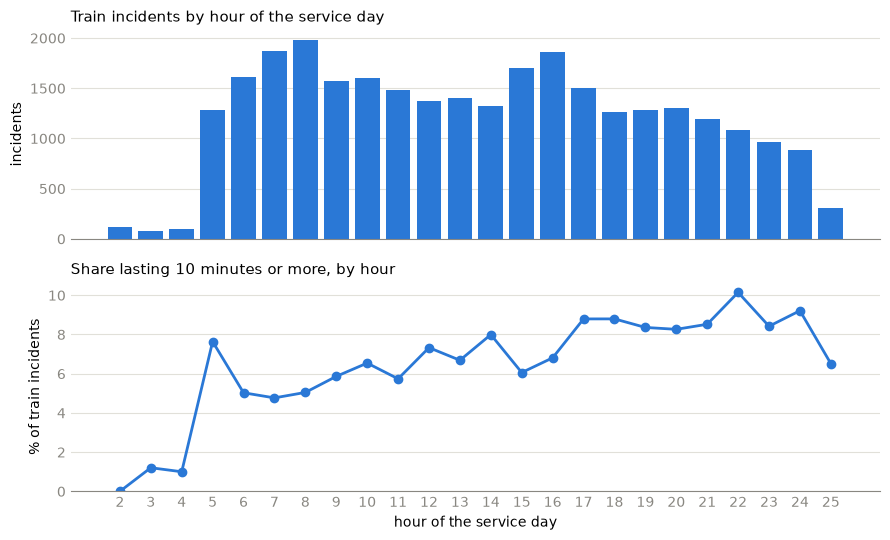

,incidents,share_5min_plus,share_10min_plus,share_15min_plus,share_30min_plus
start_hour,,,,,
2,121,0.0%,0.0%,0.0%,0.0%
3,83,1.2%,1.2%,0.0%,0.0%
4,100,1.0%,1.0%,1.0%,1.0%
5,1283,18.6%,7.6%,4.8%,2.6%
6,1611,19.6%,5.0%,2.9%,1.3%
7,1867,19.8%,4.8%,2.2%,0.8%
8,1982,21.3%,5.0%,2.8%,1.3%
9,1569,20.8%,5.9%,3.3%,1.5%
10,1605,24.0%,6.5%,3.2%,1.4%


In [31]:
# Hour of the service day (hours 24 and 25 are after midnight).
train["start_hour"] = train["start_minutes"] // 60
by_hour = eda.duration_summary(train, "start_hour")

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].bar(by_hour.index, by_hour["incidents"], color=eda.SERIES_COLORS[0], width=0.8)
eda.style_axes(axes[0], "Train incidents by hour of the service day", "incidents")
axes[1].plot(by_hour.index, by_hour["share_10min_plus"] * 100,
             color=eda.SERIES_COLORS[0], linewidth=2, marker="o")
axes[1].set_ylim(0, None)
axes[1].set_xticks(by_hour.index)
axes[1].set_xlabel("hour of the service day")
eda.style_axes(axes[1], "Share lasting 10 minutes or more, by hour", "% of train incidents")
plt.tight_layout()
plt.show()
by_hour.style.format({c: "{:.1%}" for c in by_hour.columns if c.startswith("share")})

In [32]:
# Day of week (1 = Monday ... 7 = Sunday), based on the service date.
by_weekday = eda.duration_summary(train, "weekday")
by_weekday.style.format({c: "{:.1%}" for c in by_weekday.columns if c.startswith("share")})

,incidents,share_5min_plus,share_10min_plus,share_15min_plus,share_30min_plus
weekday,,,,,
1,4294,21.8%,6.8%,3.7%,1.9%
2,4591,22.2%,6.2%,3.1%,1.5%
3,4334,21.1%,7.2%,4.1%,1.8%
4,4443,22.3%,7.1%,4.1%,2.2%
5,4708,21.9%,6.8%,4.0%,1.6%
6,3525,21.8%,7.1%,3.5%,1.8%
7,3272,23.0%,7.8%,4.1%,1.8%


In [33]:
# Location: how concentrated are incidents, and do locations differ in duration?
location_counts = train["location"].value_counts()
print(f"Distinct locations among train incidents: {len(location_counts)}")
print(f"Locations with fewer than 30 train incidents: {(location_counts < 30).sum()}")
print(f"Share of train incidents in the 15 busiest locations: {location_counts.head(15).sum() / len(train):.1%}")

by_location = eda.duration_summary(train, "location").sort_values("incidents", ascending=False)
by_location.head(15).style.format({c: "{:.1%}" for c in by_location.columns if c.startswith("share")})

Distinct locations among train incidents: 229
Locations with fewer than 30 train incidents: 118
Share of train incidents in the 15 busiest locations: 45.3%


,incidents,share_5min_plus,share_10min_plus,share_15min_plus,share_30min_plus
location,,,,,
Berri-UQAM,2231,15.6%,3.4%,1.5%,0.4%
Montmorency,1286,10.1%,1.2%,0.5%,0.3%
Côte-Vertu,974,10.8%,2.1%,0.8%,0.3%
Snowdon,963,14.7%,3.6%,1.6%,0.5%
Angrignon,949,15.4%,3.0%,0.6%,0.2%
Honorée-Beaugrand,943,17.3%,3.6%,1.2%,1.0%
Berri L-2,840,15.1%,2.3%,0.7%,0.2%
Lionel-Groulx,783,17.5%,4.7%,2.4%,1.0%
Longueuil,767,13.2%,3.7%,2.5%,1.2%


## 4. Findings from the exploration

Each finding is tagged **solid** (directly supported by the data),
**tentative** (a pattern with more than one possible explanation) or
**not answerable** (the data cannot settle it).

**For the target decision**

1. **Solid.** Duration only varies among train incidents. All 16,394 station
   incidents are in the lowest bin.
2. **Solid.** Long incidents are rare. Of 29,167 train incidents, 22.0% last
   5 minutes or more, 7.0% last 10 minutes or more, 3.8% last 15 minutes or
   more and 1.8% last 30 minutes or more. The 30-minute group has 54 to 102
   incidents per year.
3. **Solid.** The share of incidents lasting 5 minutes or more rose from 19.0%
   in 2019 to 24.2% in 2025. The share lasting 30 minutes or more shows no
   trend (1.3% to 2.1%).
4. **Solid for longer incidents, tentative for short ones.** April to
   September 2025 has 34% fewer train incidents than the same months of 2024
   and 19% fewer than 2023.
   - *Incidents of 5 minutes or more* fall by 14% over January to September
     (853 to 736). The STM's published indicator for these incidents falls by
     10% from 2024 to 2025 (13.0 to 11.66 per million km), and month by month
     the counts in this data follow the STM's rate almost exactly (section
     2.6.4). This part of the decline also appears in the STM's own reporting,
     and the data is consistent with being complete for incidents of
     5 minutes or more, so late records are an unlikely cause.
   - *Incidents under 5 minutes* fall more (36% for April to September) and
     no published figure covers them. The data cannot say whether fewer
     happened or fewer were logged.
   - The 2025 maintenance strikes explain little: about 30 of the 850 missing
     incidents (section 2.6.1). The decline starts in April, before the first
     strike in June; the STM's monthly rate shows the same (10.9 in April and
     8.4 in May 2025).
   - 2024 is a high comparison year because of the August and September spike.
5. **Solid.** Volume dropped sharply in March 2020 and took until about 2023
   to return to the 2019 level. The August and September 2024 spike is one
   episode, not a general rise, and it has two parts:
   - *Short incidents, August and September.* 350 incidents logged with a
     rolling-stock symptom were later traced to track (`Service de la voie`)
     at terminal stations, mostly Berri-UQAM on the yellow line and
     Montmorency on the orange line; 90% are in the lowest duration bin
     (section 2.6.2).
   - *Incidents of 5 minutes or more, September only.* 138 in September 2024
     against about 89 in the other months of the year; 66 of them are
     attributed to `Service de la voie` and 60 are at Berri-UQAM. The STM's
     own monthly indicator confirms it: 19.6 per million km in September
     2024, against 9.0 to 14.7 in the other months (section 2.6.4).

   The symptom recorded at the time was wrong for most of the short
   incidents, so symptom reliability varies over time (agreement with the
   primary cause: 70.5% in 2024, 76 to 79% in other years).
6. **Solid.** Planned km explain little of the change in incident counts:
   planned km fell by about 6% from 2019 to 2021 while train incidents fell by
   about 30%. Per million planned km, the orange line has the lowest rate
   every year, and the green line's rate rises from 2021 to 2023.
7. **Not answerable.** Rates after September 2023 (no km data), rates per
   rider (no ridership data), and whether the yellow line's higher planned km
   in 2023 is real service.
8. **Tentative.** The closure hypothesis holds for a small cluster only. Six
   of the 21 mismatches with a gap of 3 hours or more are at St-Michel on
   4 to 8 and 17 October 2024, all 05:00/05:30 to 24:30, lowest duration bin,
   fixed-equipment symptom. The STM closed blue-line stations over structural
   issues at that time
   ([CTV News, 3 October 2024](https://montreal.ctvnews.ca/stm-closes-3-metro-stations-on-blue-line-due-to-structural-issues-1.7061733)),
   which fits a closure logged as an incident; the data itself does not name
   the cause. Most mismatches (384 of 525) have a gap under 30 minutes and are
   spread over many locations, so closures do not explain them. The mismatch
   share rises from 1.2% in 2019 to 2.3% in 2024.

**For the feature decision**

9. **Solid.** The fields most strongly related to duration are the ones with
   undocumented timing. With an evacuation of train and station, 76% of
   incidents last 30 minutes or more; with the emergency team, 45%; with
   material damage, 28%; with a traction power cut, 6.5%; against 1.8% overall.
10. **Not answerable.** Whether those indicators are known when the incident
    starts or are consequences of a long incident. The dictionary does not say.
11. **Solid.** Among fields recorded at the time of the incident, the symptom
    separates durations: fire, smoke or odour 11.0% at 30 minutes or more,
    fixed equipment 2.7%, train operations 0.0%.
12. **Solid.** Train incidents without a run number (19% of them) almost never
    last long: 1.7% reach 5 minutes, against 26.7% with a run number.
13. **Solid.** Incidents covering several lines are much longer (13.8% at
    30 minutes or more), but there are only 449 of them.
14. **Tentative.** Classification is drifting. Among train incidents, the
    symptom "Exploitation stations" grows from 0.8% (2019) to 8.8% (2025),
    "Exploitation trains" falls from 12.3% to about 5%, the door indicator
    falls from 14.1% to 7.5%, and incidents without a run number rise from
    14.7% to 23.0%. These may reflect reporting practice more than operations.
15. **Solid.** Missing values are not a practical problem for the symptom
    (0.5% at most per year among train incidents).
16. **Solid.** Time of day matters a little, day of week does not. Incidents
    before 05:00 are almost never long; the share lasting 10 minutes or more
    climbs from about 5% in the morning to 8 to 10% in the evening.
17. **Solid.** Location is concentrated and uneven: 229 locations, 118 of
    them with fewer than 30 train incidents; the 15 busiest hold 45% of
    incidents. Terminal stations have many short incidents.

## 5. Target definition: candidates

**Part 2: decisions.** This section lays out the evidence for the target
decision. The choice itself is recorded in the decision log in `PLAN.md`.

"Major interruption" has to be defined from the duration bin, the only
duration measure published. Four thresholds follow the bin edges: 5, 10, 15
and 30 minutes. Two populations are possible: all incidents, or train
incidents only.

In [34]:
# Positives and rate for each candidate threshold, on both populations.
rows = []
for minutes in eda.THRESHOLDS:
    positives = int((train["duration_bin_lower"] >= minutes).sum())
    rows.append({
        "target": f"{minutes} min or more",
        "positives": positives,
        "rate_among_train_incidents": positives / len(train),
        # Station incidents are never positive, so they only dilute the rate.
        "rate_among_all_incidents": positives / len(incidents),
    })
candidates = pd.DataFrame(rows).set_index("target")
candidates.style.format({"rate_among_train_incidents": "{:.1%}",
                         "rate_among_all_incidents": "{:.1%}"})

,positives,rate_among_train_incidents,rate_among_all_incidents
target,,,
5 min or more,6413,22.0%,14.1%
10 min or more,2036,7.0%,4.5%
15 min or more,1103,3.8%,2.4%
30 min or more,524,1.8%,1.2%


### 5.1 Positives per year

A temporal validation tests on a recent period, so what matters is how many
positives one year holds. 2025 covers January to September.

In [35]:
positives_by_year = pd.DataFrame({
    f"{minutes} min or more": train[train["duration_bin_lower"] >= minutes]
        .groupby("service_year").size()
    for minutes in eda.THRESHOLDS
})
positives_by_year["train_incidents"] = train.groupby("service_year").size()
positives_by_year

,5 min or more,10 min or more,15 min or more,30 min or more,train_incidents
service_year,,,,,
2019,964,275,143,67,5081
2020,799,253,146,77,3709
2021,800,262,145,75,3564
2022,896,276,157,78,4207
2023,1097,345,169,71,4497
2024,1121,396,222,102,5063
2025,736,229,121,54,3046


In [36]:
# The same as a rate per year, to see how stable each definition is over time.
rate_by_year = positives_by_year.drop(columns="train_incidents").div(
    positives_by_year["train_incidents"], axis=0
)
print("Lowest and highest yearly rate, and their ratio:")
print(pd.DataFrame({"lowest": rate_by_year.min(), "highest": rate_by_year.max(),
                    "highest_to_lowest": rate_by_year.max() / rate_by_year.min()}).round(3).to_string())
rate_by_year.style.format("{:.1%}")

Lowest and highest yearly rate, and their ratio:
                lowest  highest  highest_to_lowest
5 min or more    0.190    0.244              1.286
10 min or more   0.054    0.078              1.445
15 min or more   0.028    0.044              1.558
30 min or more   0.013    0.021              1.596


,5 min or more,10 min or more,15 min or more,30 min or more
service_year,,,,
2019,19.0%,5.4%,2.8%,1.3%
2020,21.5%,6.8%,3.9%,2.1%
2021,22.4%,7.4%,4.1%,2.1%
2022,21.3%,6.6%,3.7%,1.9%
2023,24.4%,7.7%,3.8%,1.6%
2024,22.1%,7.8%,4.4%,2.0%
2025,24.2%,7.5%,4.0%,1.8%


### 5.2 How noisy would evaluation be?

With few positives in a test year, any metric is imprecise. As a rough guide:
if a model caught half of the positives (recall of 50%), the 95% margin of
error on that recall is about 1.96 x sqrt(0.5 x 0.5 / n), where n is the
number of positives in the test period. This is the simple binomial formula,
used only to compare the candidates, not as a result.

In [37]:
import math

noise_rows = []
for target in rate_by_year.columns:
    for year in [2024, 2025]:
        n = int(positives_by_year.loc[year, target])
        margin = 1.96 * math.sqrt(0.5 * 0.5 / n)
        noise_rows.append({"target": target, "test_year": year, "positives": n,
                           "margin_on_50pct_recall": margin})
noise = pd.DataFrame(noise_rows).pivot(index="target", columns="test_year")
noise = noise.loc[list(rate_by_year.columns)]   # keep the 5, 10, 15, 30 order
noise.style.format({("margin_on_50pct_recall", 2024): "±{:.1%}",
                    ("margin_on_50pct_recall", 2025): "±{:.1%}"})

### 5.3 What the positives look like

For each candidate, the mix of symptoms among positives, and how many
positives carry each operational indicator. This shows what kind of event
each definition would ask a model to find.

In [38]:
profile = {}
for minutes in eda.THRESHOLDS:
    positives = train[train["duration_bin_lower"] >= minutes]
    profile[f"{minutes} min or more"] = pd.concat([
        positives["symptom"].value_counts(normalize=True).rename(lambda s: f"symptom: {s}"),
        pd.Series({
            "with traction power cut": positives["traction_power_cut"].mean(),
            "with any evacuation": (positives["evacuation"] != "Aucune").mean(),
            "with emergency team": positives["emergency_team"].mean(),
            "on several lines": (positives["line_group"] == "Multiple lines or other").mean(),
            "time/bin mismatch flag": positives["flag_time_bin_mismatch"].mean(),
        }),
    ])
# A symptom that never occurs among the positives shows as 0%.
pd.DataFrame(profile).fillna(0).style.format("{:.1%}")

,5 min or more,10 min or more,15 min or more,30 min or more
on several lines,2.3%,5.3%,8.8%,11.8%
symptom: Clientèle,39.8%,41.4%,43.7%,42.0%
symptom: Divers,0.5%,0.6%,0.4%,0.4%
symptom: Exploitation stations,0.2%,0.2%,0.4%,0.4%
symptom: Exploitation trains,3.4%,0.8%,0.1%,0.0%
"symptom: Feu, fumée, odeur, produit, etc...",4.0%,10.7%,18.1%,26.1%
symptom: Matériel roulant,31.9%,24.8%,15.9%,11.1%
symptom: Équipements fixes,20.2%,21.4%,21.5%,20.0%
time/bin mismatch flag,3.9%,4.0%,2.8%,0.2%
with any evacuation,17.7%,41.9%,58.7%,78.1%


### 5.4 Decision

Recorded as D2 in the decision log (`PLAN.md`):

- **Population:** train incidents only. Station incidents can never be positive.
- **Primary target:** 15 minutes or more (1,103 positives, 3.8%).
- **Secondary view:** 30 minutes or more, evaluated on the same model scores.
- **5 minutes or more** remains the link to the STM's published indicator in
  the reliability view; it is not treated as "major".
- **Sensitivity run:** 10 minutes or more.

Reason: 15 minutes is the lowest threshold that can be defended as "major"
in front of stakeholders. A single test year has few positives at this
threshold (121 to 222), so model comparison pools several yearly folds.

## 6. Features: candidates

Evidence for the feature decision. A field can only be used if it is known
when the incident starts. Every raw column is classified below, then the
candidate fields are compared on the chosen target (15 minutes or more).

In [39]:
# One row per raw column: when it is known, and why.
# "start"   = known when the incident starts
# "later"   = only known during or after the incident (using it would leak the outcome)
# "unknown" = the dictionary does not say when it is recorded
column_status = pd.DataFrame([
    ("Numero d'incident",   "later",   "identifier, no information"),
    ("Type d'incident",     "start",   "used to select train incidents, constant afterwards"),
    ("Cause primaire",      "later",   "dictionary: set by analysis after the incident"),
    ("Cause secondaire",    "later",   "dictionary: set by analysis after the incident"),
    ("Symptome",            "start",   "dictionary: cause attributed at the time of the incident"),
    ("Ligne",               "start",   "the four single lines; see multi-line below"),
    ("Ligne (multi-line)",  "unknown", "a list of lines may describe how far the incident spread"),
    ("Numéro de tournée",   "unknown", "whether a train run is attached; likely part of the first report"),
    ("Heure de l'incident", "start",   "start of the customer delay"),
    ("Heure de reprise",    "later",   "end of the delay: this is the outcome"),
    ("Incident en minutes", "later",   "the target is built from it"),
    ("Véhicule",            "unknown", "car number; mostly missing, may be filled in later"),
    ("Porte de voiture",    "unknown", "door number; detail likely added later"),
    ("Type de matériel",    "later",   "mirrors the secondary cause (all but 4 rows)"),
    ("Code de lieu",        "start",   "where the incident is"),
    ("Dommage matériel",    "unknown", "not documented; damage may be assessed afterwards"),
    ("KFS",                 "unknown", "emergency brake pulled by a customer; likely the triggering event"),
    ("Porte",               "unknown", "a door is involved; likely the triggering event"),
    ("Urgence métro",       "unknown", "emergency team called by the control room, during the incident"),
    ("CAT",                 "unknown", "traction power cut, a response during the incident"),
    ("Évacuation",          "unknown", "a response during the incident"),
    ("Année civile",        "start",   "calendar; not used as a feature (would encode reporting drift)"),
    ("Année civile/mois",   "start",   "calendar; redundant"),
    ("Mois calendrier",     "start",   "calendar"),
    ("Jour du mois",        "start",   "calendar; no expected relation"),
    ("Jour de la semaine",  "start",   "calendar"),
    ("Jour calendaire",     "start",   "calendar; used to order incidents in time"),
], columns=["raw_column", "known_at", "reason"])
print(column_status["known_at"].value_counts().to_string())
column_status

known_at
start      11
unknown    10
later       6


,raw_column,known_at,reason
0,Numero d'incident,later,"identifier, no information"
1,Type d'incident,start,"used to select train incidents, constant afterwards"
2,Cause primaire,later,dictionary: set by analysis after the incident
3,Cause secondaire,later,dictionary: set by analysis after the incident
4,Symptome,start,dictionary: cause attributed at the time of the incident
5,Ligne,start,the four single lines; see multi-line below
6,Ligne (multi-line),unknown,a list of lines may describe how far the incident spread
7,Numéro de tournée,unknown,whether a train run is attached; likely part of the first report
8,Heure de l'incident,start,start of the customer delay
9,Heure de reprise,later,end of the delay: this is the outcome


### 6.1 How each candidate relates to the target

Rate of incidents of 15 minutes or more for each value of each candidate
field. `lift` is that rate divided by the overall rate (3.8%): 1 means no
information, 4 means four times the usual risk.

In [40]:
train["is_major"] = train["duration_bin_lower"] >= 15
overall_rate = train["is_major"].mean()

# Two more candidate fields built from columns known at the start.
train["between_stations"] = train["location"].str.contains("/")   # e.g. "Crémazie/Sauvé"

def target_rate(field):
    """Incidents, positives, rate and lift for each value of `field`."""
    table = train.groupby(field, observed=True)["is_major"].agg(["size", "sum", "mean"])
    table.columns = ["incidents", "positives", "rate"]
    table["lift"] = table["rate"] / overall_rate
    table.insert(0, "field", field)
    return table.rename_axis("value").reset_index()

groups = {
    "start": ["symptom", "between_stations", "line_group"],
    "unknown, likely part of the first report": ["has_run_number", "has_vehicle",
                                                 "emergency_brake", "door_involved"],
    "unknown, a response during the incident": ["traction_power_cut", "emergency_team",
                                                "evacuation", "material_damage"],
}
pieces = []
for known_at, fields in groups.items():
    for field in fields:
        piece = target_rate(field)
        piece.insert(0, "known_at", known_at)
        pieces.append(piece)
rates_by_field = pd.concat(pieces, ignore_index=True)
print(f"Overall rate: {overall_rate:.1%} ({train['is_major'].sum()} of {len(train)})")
rates_by_field.style.format({"rate": "{:.1%}", "lift": "{:.2f}"})

Overall rate: 3.8% (1103 of 29167)


,known_at,value,field,incidents,positives,rate,lift
0,start,Clientèle,symptom,13095,482,3.7%,0.97
1,start,Divers,symptom,97,4,4.1%,1.09
2,start,Exploitation stations,symptom,944,4,0.4%,0.11
3,start,Exploitation trains,symptom,2071,1,0.0%,0.01
4,start,"Feu, fumée, odeur, produit, etc...",symptom,1250,199,15.9%,4.21
5,start,Matériel roulant,symptom,7750,175,2.3%,0.60
6,start,Équipements fixes,symptom,3877,237,6.1%,1.62
7,start,False,between_stations,27308,907,3.3%,0.88
8,start,True,between_stations,1859,196,10.5%,2.79
9,start,Ligne bleue,line_group,3232,100,3.1%,0.82


In [41]:
# Hour of the service day, weekday and month: lowest and highest lift among their values.
for field in ["start_hour", "weekday", "service_month"]:
    table = target_rate(field)
    table = table[table["incidents"] >= 300]      # ignore the nearly empty early hours
    print(f"{field}: lift from {table['lift'].min():.2f} to {table['lift'].max():.2f}")

# Location: rate across the locations with at least 100 train incidents.
by_place = target_rate("location")
busy = by_place[by_place["incidents"] >= 100]
print(f"\nLocations with 100+ incidents: {len(busy)} of {len(by_place)}, "
      f"holding {busy['incidents'].sum() / len(train):.0%} of train incidents")
print(f"Their rate ranges from {busy['rate'].min():.1%} to {busy['rate'].max():.1%}")

start_hour: lift from 0.58 to 1.52
weekday: lift from 0.82 to 1.09
service_month: lift from 0.83 to 1.16

Locations with 100+ incidents: 76 of 229, holding 88% of train incidents
Their rate ranges from 0.5% to 8.6%


### 6.2 Is recent activity on the line informative?

A candidate "history" feature: the number of train incidents on the same line
in the 60 minutes before this one. It uses only earlier incidents, and it
leaves out incidents starting in the same minute (section 2.6.6).

In [42]:
# A real timestamp for the start: service date plus minutes into the service day.
train["start_timestamp"] = train["service_date"] + pd.to_timedelta(train["start_minutes"], unit="m")
ordered = train.sort_values("start_timestamp")

# For each line, count incidents in the 60 minutes before each incident.
# closed="left" leaves out the current minute, so an incident never counts
# itself or a twin that starts at the same time.
train["incidents_prev_60min"] = 0.0
for line, group in ordered.groupby("line"):
    counts = (group.set_index("start_timestamp")["start_minutes"]
              .rolling("60min", closed="left").count())
    train.loc[group.index, "incidents_prev_60min"] = counts.fillna(0).to_numpy()

train["prev_60min_band"] = train["incidents_prev_60min"].clip(upper=3).astype(int)   # 3 means "3 or more"
target_rate("prev_60min_band").style.format({"rate": "{:.1%}", "lift": "{:.2f}"})

,value,field,incidents,positives,rate,lift
0,0,prev_60min_band,22575,885,3.9%,1.04
1,1,prev_60min_band,5300,179,3.4%,0.89
2,2,prev_60min_band,1022,29,2.8%,0.75
3,3,prev_60min_band,270,10,3.7%,0.98


### 6.3 Is the relation between symptom and target stable over time?

Rate of incidents of 15 minutes or more by symptom and year. A relation that
changes over time limits how well a model trained on the past can predict.

In [43]:
symptom_by_year = train.pivot_table(index="service_year", columns="symptom",
                                    values="is_major", aggfunc="mean")
symptom_by_year.style.format("{:.1%}")

symptom,Clientèle,Divers,Exploitation stations,Exploitation trains,"Feu, fumée, odeur, produit, etc...",Matériel roulant,Équipements fixes
service_year,,,,,,,
2019,2.8%,4.2%,2.5%,0.0%,8.0%,1.8%,6.2%
2020,3.8%,0.0%,0.0%,0.0%,9.8%,1.9%,10.7%
2021,3.6%,4.2%,1.3%,0.0%,15.6%,2.1%,6.5%
2022,3.8%,10.0%,1.5%,0.4%,19.8%,1.3%,4.5%
2023,3.7%,0.0%,0.0%,0.0%,15.5%,2.7%,5.0%
2024,4.4%,0.0%,0.0%,0.0%,24.0%,3.1%,5.3%
2025,3.6%,0.0%,0.0%,0.0%,26.0%,3.1%,6.1%


### 6.4 Decision and resulting feature sets

Recorded as D3 in the decision log (`PLAN.md`) and implemented in
`src/features.py`:

- **Headline set:** the fields known at the start plus three first-report
  fields (train run attached, door involved, emergency brake).
- **Lower bound:** the strict set, fields known at the start only.
- **Upper bound:** adds the response indicators. Reported only as "if these
  indicators were known in the first minutes"; not a usable model.
- **Ablation:** the headline set without "train run attached".
- No history features and no year feature.
- Multi-line incidents take their first listed line, and line lists are
  removed from location codes, so "the incident spread" cannot be learned
  through the back door.

The cells below build the modelling table and check it.

In [44]:
from src import features

model_table = features.build_model_table(incidents)
print(f"Rows: {len(model_table):,} (train incidents)")
print("Positives per target:", {name: int(model_table[name].sum()) for name in features.TARGETS})

# Location groups must be learned on training rows only. As an illustration,
# learn them on 2019-2023 and apply them to every row.
example_training = model_table[model_table["service_year"] <= 2023]
kept_locations = features.fit_location_groups(example_training)
model_table = features.add_location_group(model_table, kept_locations)
print(f"Locations kept as their own value: {len(kept_locations)}; the rest become '{features.OTHER_LOCATION}'")

# Each feature set: size, missing values, and a check that no excluded column is present.
for name in features.FEATURE_SETS:
    X = features.feature_matrix(model_table, name)   # raises an error if a leak is found
    excluded_present = set(X.columns) & set(features.NEVER_FEATURES)
    print(f"{name:22s} {X.shape[1]:2d} features, {int(X.isna().sum().sum())} missing values, "
          f"excluded columns present: {len(excluded_present)}")

Rows: 29,167 (train incidents)
Positives per target: {'is_major': 1103, 'is_severe': 524, 'is_10min_plus': 2036}
Locations kept as their own value: 64; the rest become 'Autre lieu'
strict                  7 features, 0 missing values, excluded columns present: 0
headline               10 features, 0 missing values, excluded columns present: 0
headline_without_run    9 features, 0 missing values, excluded columns present: 0
upper_bound            15 features, 0 missing values, excluded columns present: 0


In [45]:
# How raw line values were mapped. Multi-line values take their first listed line.
line_mapping = pd.DataFrame({
    "raw_line": incidents.loc[model_table.index, "line"],
    "line_first": model_table["line_first"],
    "several_lines": model_table["several_lines"],
})
print(line_mapping[~line_mapping["raw_line"].isin(data.SINGLE_LINES)]
      .value_counts().sort_index().to_string())

# Rate of the target by assigned line: no value stands out any more.
model_table.groupby("line_first")["is_major"].agg(["size", "mean"]).round(3)

raw_line          line_first      several_lines
02-avr            Ligne inconnue  False              1
Ligne 1, 2        Ligne verte     True             118
Ligne 1, 2, 4     Ligne verte     True              80
Ligne 1, 2, 4, 5  Ligne verte     True              14
Ligne 1, 2, 5     Ligne verte     True               6
Ligne 1, 4        Ligne verte     True               1
Ligne 1, 5        Ligne verte     True               1
Ligne 2, 1        Ligne orange    True              43
Ligne 2, 1, 4     Ligne orange    True               7
Ligne 2, 1, 5     Ligne orange    True               4
Ligne 2, 4        Ligne orange    True               5
Ligne 2, 5        Ligne orange    True              48
Ligne 4, 1        Ligne jaune     True               2
Ligne 4, 1, 2     Ligne jaune     True               3
Ligne 4, 2, 1     Ligne jaune     True               3
Ligne 5, 1        Ligne bleue     True               1
Ligne 5, 2        Ligne bleue     True              15
Non affecté      

,size,mean
line_first,,
Ligne bleue,3248,0.033
Ligne inconnue,98,0.031
Ligne jaune,2161,0.030
Ligne orange,11613,0.037
Ligne verte,12047,0.041


## 7. Validation and metrics: candidates

Evidence for the validation decision. No model is fitted here. The question
is how to split the data in time so that each test period comes after its
training period, and how many positives each test period holds.

In [46]:
from src import validation

# Expanding window: test on 2021, 2022, 2023, 2024, each time training on all earlier years.
expanding = validation.rolling_origin_folds(model_table, test_years=[2021, 2022, 2023, 2024])
expanding_table = validation.describe_folds(model_table, expanding, target="is_major")
print(f"Pooled test positives over the folds: {expanding_table['test_positives'].sum()}")
expanding_table.style.format({"test_rate": "{:.1%}"})

Pooled test positives over the folds: 693


,train_years,train_rows,train_positives,test_rows,test_positives,test_rate,train_ends_before_test,shared_rows
test_year,,,,,,,,
2021,2019-2020,8790,289,3564,145,4.1%,True,0
2022,2019-2021,12354,434,4207,157,3.7%,True,0
2023,2019-2022,16561,591,4497,169,3.8%,True,0
2024,2019-2023,21058,760,5063,222,4.4%,True,0


In [47]:
# Sliding window: the same test years, training only on the three years before each.
sliding = validation.rolling_origin_folds(model_table, test_years=[2021, 2022, 2023, 2024],
                                          max_train_years=3)
validation.describe_folds(model_table, sliding, target="is_major").style.format({"test_rate": "{:.1%}"})

,train_years,train_rows,train_positives,test_rows,test_positives,test_rate,train_ends_before_test,shared_rows
test_year,,,,,,,,
2021,2019-2020,8790,289,3564,145,4.1%,True,0
2022,2019-2021,12354,434,4207,157,3.7%,True,0
2023,2020-2022,11480,448,4497,169,3.8%,True,0
2024,2021-2023,12268,471,5063,222,4.4%,True,0


In [48]:
# Final holdout: 2025 (January to September), trained on everything before it.
holdout = validation.rolling_origin_folds(model_table, test_years=[2025])
holdout_table = validation.describe_folds(model_table, holdout, target="is_major")
# The same holdout seen through the secondary target (30 minutes or more).
holdout_table["test_positives_30min"] = int(model_table.loc[holdout[0]["test"], "is_severe"].sum())
holdout_table.style.format({"test_rate": "{:.1%}"})

,train_years,train_rows,train_positives,test_rows,test_positives,test_rate,train_ends_before_test,shared_rows,test_positives_30min
test_year,,,,,,,,,
2025,2019-2024,26121,982,3046,121,4.0%,True,0,54


In [49]:
# Incidents are not fully independent: several can start on the same service
# day. If uncertainty is estimated by resampling, resampling whole days keeps
# such incidents together. How many days and positive days does 2025 hold?
holdout_rows = model_table[holdout[0]["test"]]
per_day = holdout_rows.groupby("service_date")["is_major"].agg(["size", "sum"])
print(f"Holdout days: {len(per_day)}, days with at least one major incident: {(per_day['sum'] > 0).sum()}")
print(f"Days with two or more major incidents: {(per_day['sum'] >= 2).sum()}")

Holdout days: 272, days with at least one major incident: 96
Days with two or more major incidents: 22


### 7.1 Decision

Recorded as D4 in the decision log (`PLAN.md`):

- **Model comparison:** expanding window, test years 2021 to 2024, results
  shown per fold and pooled (693 test positives).
- **Final holdout:** 2025 (January to September, 121 positives), trained on
  2019 to 2024, used once and never to choose between models.
- **Metrics:** PR-AUC (primary, against the base rate); recall and precision
  among the 5% and 10% highest-scored incidents; calibration (Brier score
  against a constant-rate baseline, predicted against observed by score
  band); ROC-AUC as a secondary reference.
- **Baselines:** a constant rate, and a symptom-only rate table.
- **Uncertainty:** bootstrap on the holdout, resampling whole service days,
  1,000 resamples.